In [139]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from random import shuffle
import random
random.seed(42)

In [140]:
r_scape = pickle.load(open("data/eval_rscape.pickle", "rb"))
phylo_score = pickle.load(open("data/eval_phyloscore.pickle", "rb"))
datasets = list(map(str.strip, open("3d.txt", "r")))

In [141]:
np.array([r_scape[(d, "GTp")][1] for d in datasets]).mean() ,np.array([r_scape[(d, "GT")][1] for d in datasets]).mean()

(np.float64(0.6789628378088932), np.float64(0.6133778310400462))

In [142]:
# Does the analysis removing all the hyper parameters with do average product corrections or average sum corrections
no_corrections = True
if no_corrections:
    r_scape = { key: value for key, value in r_scape.items() if not (key[1].endswith("p")  or key[1].endswith("a")) }
    phylo_score = { key: value for key, value in phylo_score.items() if key[4] == 'None' }

In [143]:
def extract_hyperparameters(dict):
    keys = [k[1:] for k in dict.keys()]
    return set(keys)

In [144]:
def best_hyper(dict, train_set):
    best_score = -1
    best_hyperparameters = None
    for hyper in extract_hyperparameters(dict):
        score = 0
        for dataset in train_set:
            score += dict[(dataset, *hyper)][1]
        
        if score > best_score:
            best_score = score
            best_hyperparameters = hyper
    return best_hyperparameters

In [145]:
best_hyper(phylo_score, datasets)

('0.25', '0.0', 'optdiff', 'None')

In [146]:
def cross_validation(data, per_dataset_results : dict, selected_hyper : set, splits=5):
    local_datasets = list(datasets)
    # shuffle the datasets
    shuffle(local_datasets)

    #split in splits folds
    numpy = np.array(local_datasets)
    folds = np.array_split(numpy, splits)

    results = []
    for i in range(splits):
        test = set(folds[i])
        train = set(numpy) - test

        best_hyperparameters = best_hyper(data, train)
        selected_hyper.add(best_hyperparameters)
        for dataset in test:
            results.append(data[(dataset, *best_hyperparameters)][1])
            if dataset not in per_dataset_results:
                per_dataset_results[dataset] = []
            per_dataset_results[dataset].append(data[(dataset, *best_hyperparameters)][1])
        
    return np.mean(results) * 100

In [147]:
rscape_per_dataset = {}
rscape_hyperparameters = set()
phylo_score_per_dataset = {}
phylo_score_hyperparameters = set()
results_rscape = [cross_validation(r_scape, rscape_per_dataset, rscape_hyperparameters) for _ in range(1000)]
results_phyloscore = [cross_validation(phylo_score, phylo_score_per_dataset, phylo_score_hyperparameters) for _ in range(1000)]

In [148]:
for hyper in phylo_score_hyperparameters:
    print(hyper, np.mean([phylo_score[(dataset, *hyper)][1] for dataset in datasets]))

('0.5', '0.0', 'optdiff', 'None') 0.7032408683499352
('0.5', '0.1', 'optdiff', 'None') 0.7033137369598693
('0.25', '0.0', 'optdiff', 'None') 0.7040068935457482
('0.5', '0.01', 'optdiff', 'None') 0.7031562803177177
('0.25', '0.01', 'optdiff', 'None') 0.7037857916106859


In [149]:
for hyper in rscape_hyperparameters:
    print(hyper, np.mean([r_scape[(dataset, *hyper)][1] for dataset in datasets]))

('CHI',) 0.6087287911239722
('GT',) 0.6133778310400462


In [150]:
def scatter_compare_with_diagonal(dict1, dict2, label1='Dataset 1', label2='Dataset 2', figsize=(8, 8)):
   
    # Get common categories
    common_keys = sorted(set(dict1.keys()) & set(dict2.keys()))
    
    if not common_keys:
        raise ValueError("Dictionaries have no common keys")
    
    medians1 = []
    medians2 = []
    errors1 = []
    errors2 = []
    
    for key in common_keys:
        data1 = dict1[key]
        data2 = dict2[key]
        
        median1 = np.median(data1)
        median2 = np.median(data2)
        medians1.append(median1)
        medians2.append(median2)
        
        errors1.append([np.abs(np.median(data1) - np.min(data1)), np.abs(np.max(data1) - np.median(data1))])
        errors2.append([np.abs(np.median(data2) - np.min(data2)), np.abs(np.max(data2) - np.median(data2))])
    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add diagonal line (y=x)
    min_val = 0
    max_val = 1
    ax.plot([min_val, max_val], 
            [min_val, max_val], 
            'k--', alpha=0.5)
    
    # Add error bars (horizontal and vertical)
    if not no_corrections:
        ax.errorbar(medians1, medians2,
                   yerr=np.array(errors2).T,
                   fmt='o', capsize=3, capthick=1, elinewidth=1,
                   color='blue', alpha=0.7, markersize=2,
                   label=f'{label1} vs {label2}')
    else:
        ax.errorbar(medians1, medians2,
                   yerr=np.array(errors2).T,
                   xerr=np.array(errors1).T,
                   fmt='x', capsize=0, capthick=1, elinewidth=1,
                   color='blue', alpha=0.1, markersize=0, label=f'Crossvalidation uncertainty')
        ax.scatter(medians1, medians2,
                   color='blue', alpha=0.7, s=4,
                   label=f'{label1} vs {label2} medians')
        
    
    # Customize plot
    ax.set_xlabel(f'{label1} (Average Precision)', fontsize=12)
    ax.set_ylabel(f'{label2} (Average Precision)', fontsize=12)
    ax.set_title(f'Scatter Plot Comparison: {label1} vs {label2}', fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    ax.set_aspect('equal')
    
    plt.tight_layout()
    return fig, ax

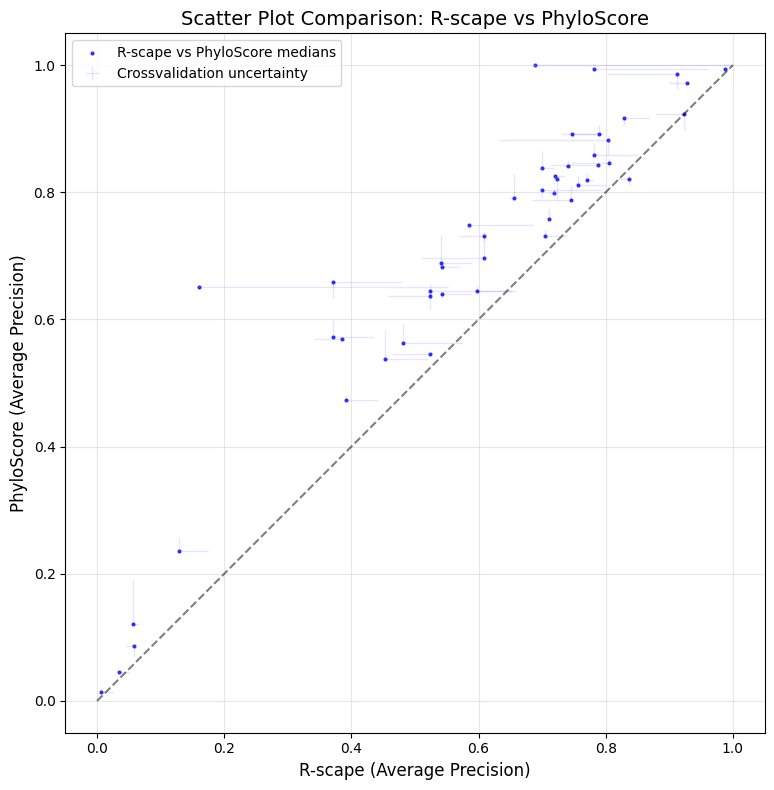

In [151]:
fig, _ =scatter_compare_with_diagonal(rscape_per_dataset, phylo_score_per_dataset, label1='R-scape', label2='PhyloScore')
if no_corrections:
    fig.savefig("cross_validation_scatter_no_corrections.pdf")
else:
    fig.savefig("cross_validation_scatter.pdf")

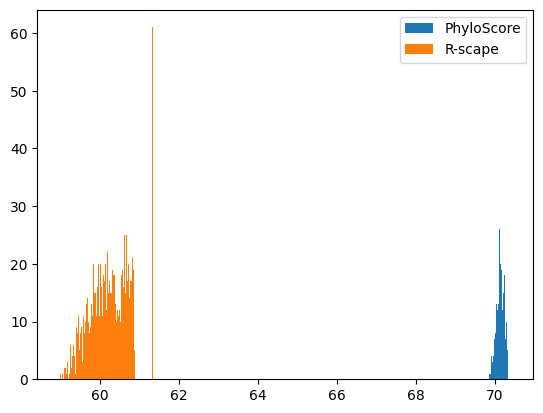

In [152]:
plt.hist(results_phyloscore, bins=100, label='PhyloScore')
#plot a line where rscape performance is
if no_corrections:
    plt.hist(results_rscape, bins=100, label='R-scape')
else:
    plt.axvline(np.mean(results_rscape), color='red', linestyle='dashed', linewidth=1, label='R-scape')
plt.legend()
if no_corrections:
    plt.savefig("cross_validation_results_no_corrections.pdf")
else:
    plt.savefig("cross_validation_results.pdf")

In [153]:
all_hyper = extract_hyperparameters(phylo_score)

In [36]:
def plot_variation_per_hyperparameter(phylo_score):
    all_hyper = extract_hyperparameters(phylo_score)
    num_types = len(next(iter(all_hyper)))
    
    # Create a 2x2 grid of subplots
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    # Flatten axes for easy indexing (optional)
    axes = axes.flatten()
    
    str_types = ["lambda", "lambda_MI", "score type", "correction type"]
    
    for type in range(num_types):
        hyperparameters = sorted(list(set(h[type] for h in all_hyper)), key=lambda x: float(x) if x.replace('.', '', 1).isdigit() else x)
        max_values = []
        for hyper in hyperparameters:
            values = [np.array([phylo_score[(dataset, *h)][1] for dataset in datasets]).mean() for h in all_hyper if h[type] == hyper]
            max = np.max(values)
            max_values.append(max)
            print(f"Type {type}, Hyperparameter {hyper}: Max AP = {max:.4f}")
        axes[type].bar(list(hyperparameters), max_values)
        axes[type].set_ylabel('Maximum Average Precision')
        axes[type].set_ylim(0.65, 0.72)
        axes[type].set_title(f'Effect of {str_types[type]}')
        axes[type].set_xticklabels(hyperparameters, rotation=90)
    plt.tight_layout()
    plt.savefig("hyperparameter_variation.pdf")
    plt.show()
    

Type 0, Hyperparameter 0.05: Max AP = 0.6906
Type 0, Hyperparameter 0.1: Max AP = 0.6984
Type 0, Hyperparameter 0.25: Max AP = 0.7090
Type 0, Hyperparameter 0.5: Max AP = 0.7148
Type 0, Hyperparameter 1.0: Max AP = 0.7136
Type 0, Hyperparameter 2.5: Max AP = 0.7127
Type 0, Hyperparameter 5.0: Max AP = 0.7085
Type 1, Hyperparameter 0.0: Max AP = 0.7145
Type 1, Hyperparameter 0.01: Max AP = 0.7148
Type 1, Hyperparameter 0.1: Max AP = 0.7147
Type 1, Hyperparameter 1.0: Max AP = 0.7133
Type 1, Hyperparameter 10.0: Max AP = 0.7089
Type 2, Hyperparameter lldiff: Max AP = 0.7127
Type 2, Hyperparameter optdiff: Max AP = 0.7148
Type 3, Hyperparameter APC: Max AP = 0.7148
Type 3, Hyperparameter ASC: Max AP = 0.7147
Type 3, Hyperparameter None: Max AP = 0.7040


/tmp/ipykernel_2406638/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_2406638/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_2406638/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_2406638/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)


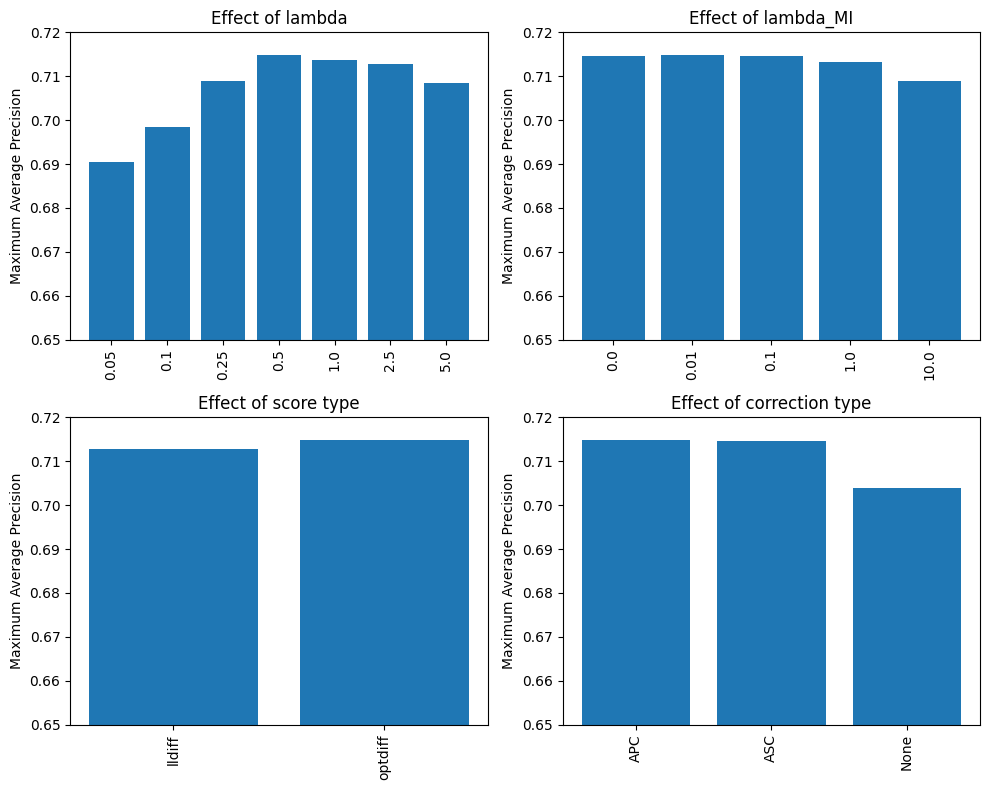

In [37]:
plot_variation_per_hyperparameter(phylo_score)

In [21]:
GT = [r_scape[(d, "GT")][1] for d in datasets]
GTp = [r_scape[(d, "GTp")][1] for d in datasets]

In [22]:
phylo_no_correction = [phylo_score[(d, '1.0', '0.0', 'optdiff', 'APC')][1] for d in datasets]

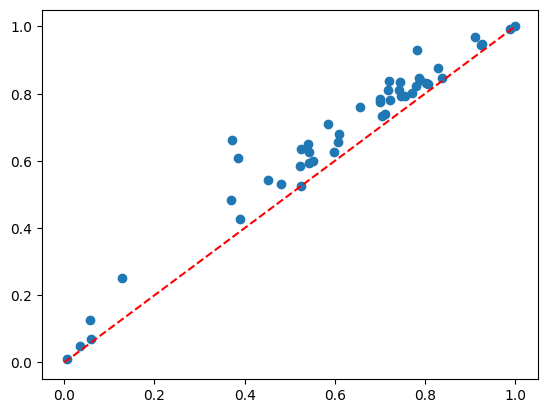

In [23]:
plt.scatter(GT, GTp)
plt.plot([0, 1], [0, 1], 'r--')

In [24]:
phylo_score_no_correction = [phylo_score[(d, '0.5', '0.01', 'optdiff', 'None')][1] for d in datasets]

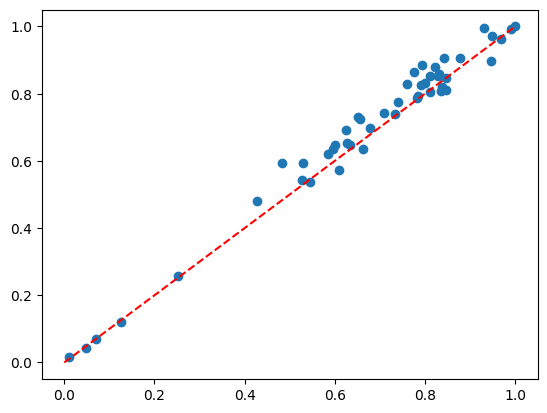

In [25]:
plt.scatter(GTp, phylo_score_no_correction)
plt.plot([0, 1], [0, 1], 'r--')